In [ ]:
import pandas as pd
import numpy as np 
import time 
df=pd.read_csv("HousingData.csv")

In [ ]:
print(df.columns)

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')


In [ ]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [ ]:
print(df.shape)

(506, 14)


In [ ]:
print(df.describe())

             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  486.000000  486.000000  486.000000  486.000000  506.000000  506.000000   
mean     3.611874   11.211934   11.083992    0.069959    0.554695    6.284634   
std      8.720192   23.388876    6.835896    0.255340    0.115878    0.702617   
min      0.006320    0.000000    0.460000    0.000000    0.385000    3.561000   
25%      0.081900    0.000000    5.190000    0.000000    0.449000    5.885500   
50%      0.253715    0.000000    9.690000    0.000000    0.538000    6.208500   
75%      3.560263   12.500000   18.100000    0.000000    0.624000    6.623500   
max     88.976200  100.000000   27.740000    1.000000    0.871000    8.780000   

              AGE         DIS         RAD         TAX     PTRATIO           B  \
count  486.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean    68.518519    3.795043    9.549407  408.237154   18.455534  356.674032   
std     27.999513    2.1057

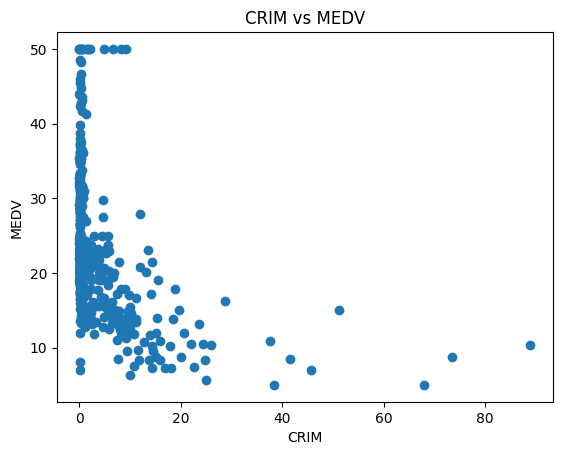

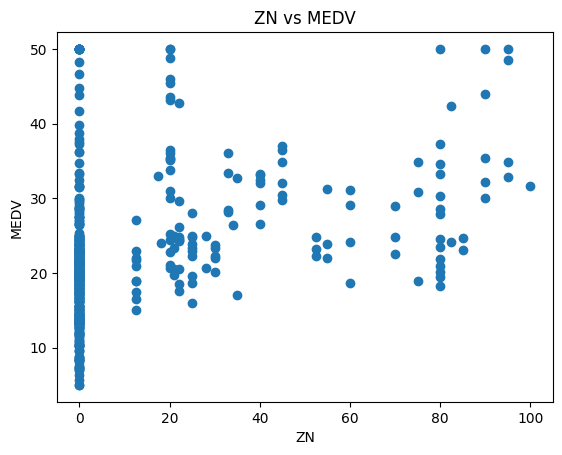

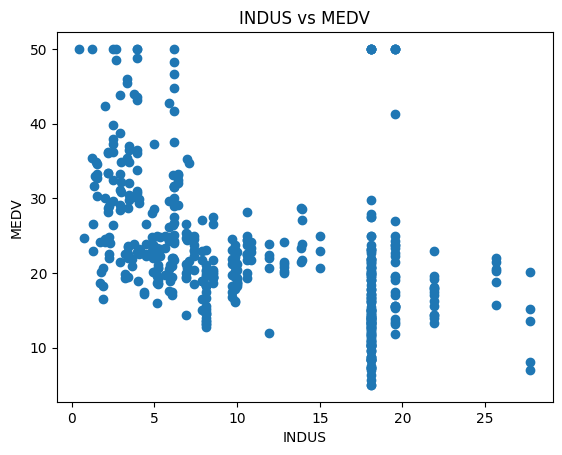

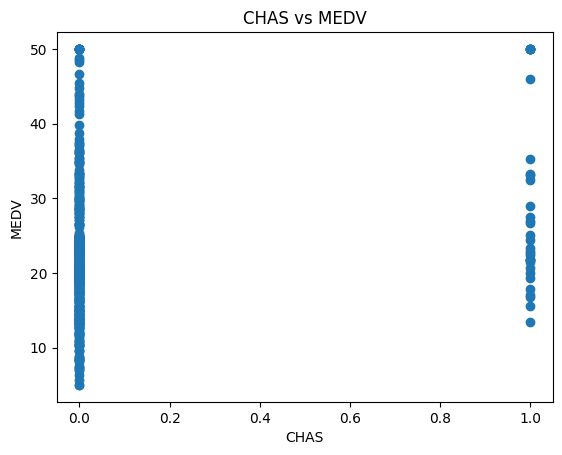

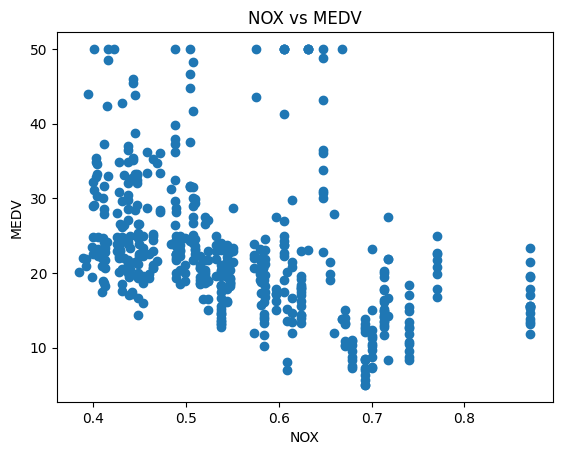

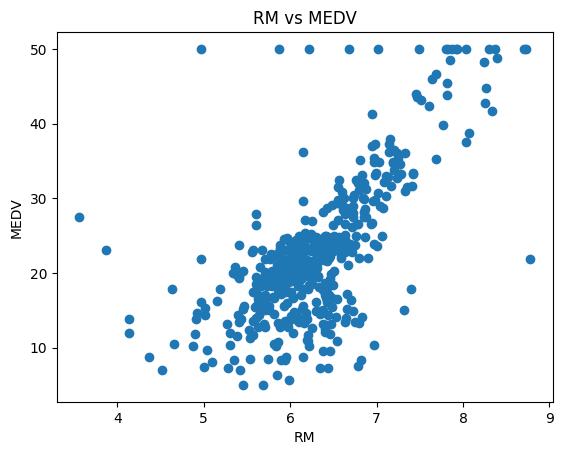

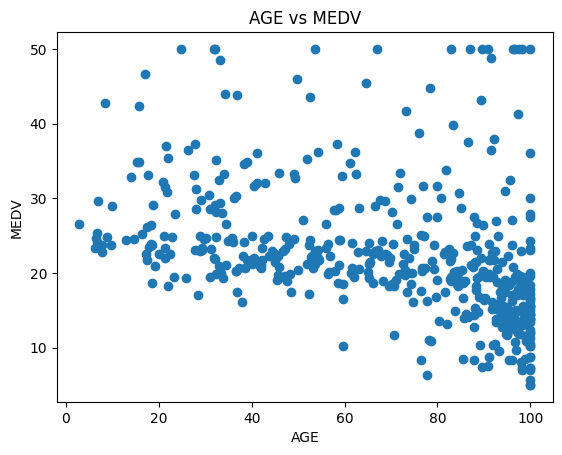

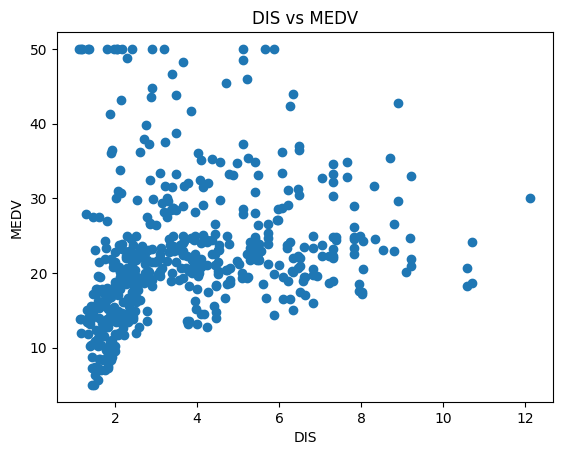

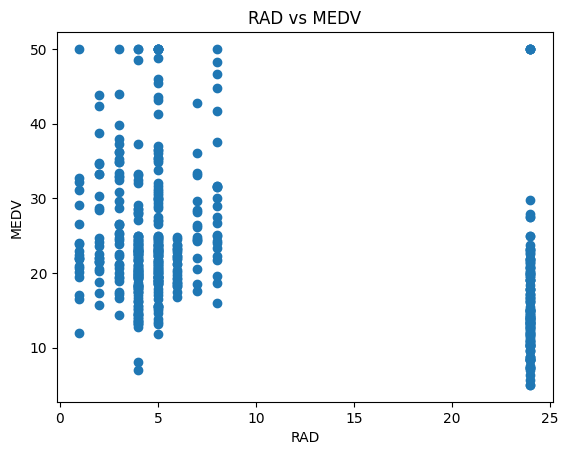

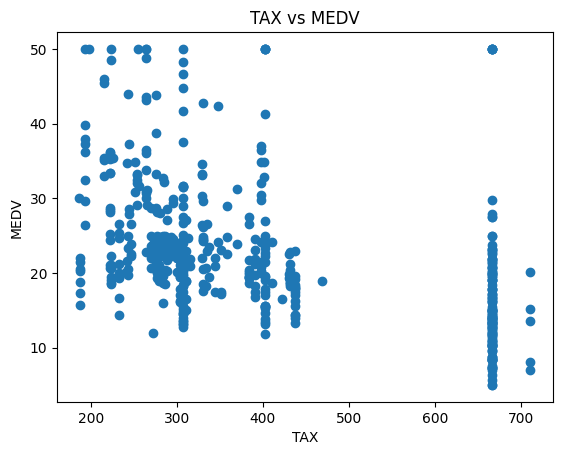

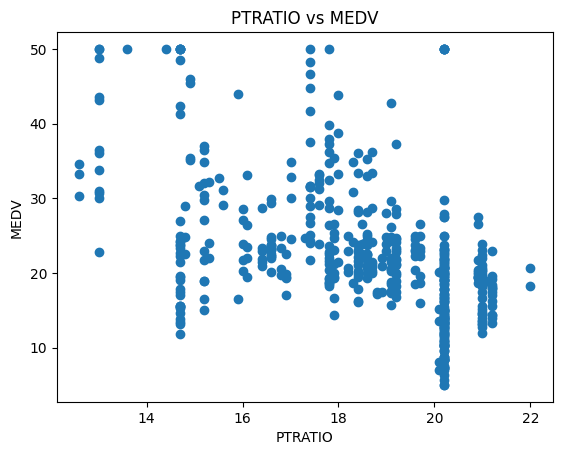

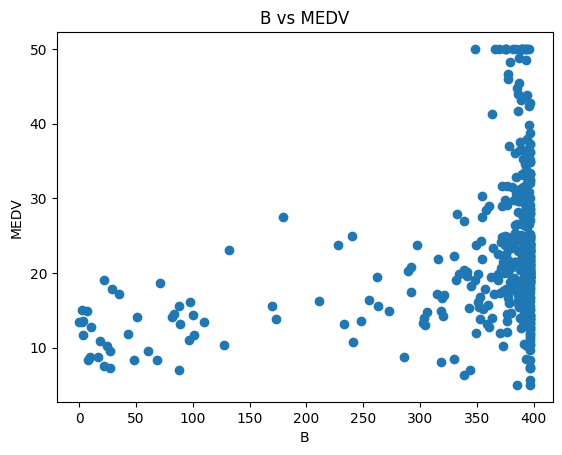

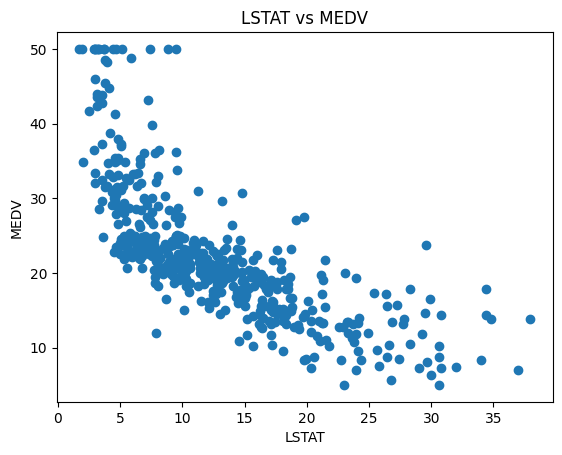

In [ ]:
import matplotlib.pyplot as plt
X = df.drop("MEDV", axis=1)
y = df["MEDV"]
for feature in X.columns:
    plt.scatter(df[feature], y)
    plt.xlabel(feature)
    plt.ylabel("MEDV")
    plt.title(feature + " vs MEDV")
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
df = df.dropna()
X = df.drop("MEDV", axis=1)
y = df["MEDV"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

Training data: (236, 13)
Validation data: (79, 13)
Test data: (79, 13)


In [ ]:
print("Mean:")
print(df.mean(numeric_only=True))
print("\nStandard Deviation:")
print(df.std(numeric_only=True))
print("\nCorrelation:")
print(df.corr(numeric_only=True))

Mean:
CRIM         3.690136
ZN          11.460660
INDUS       11.000863
CHAS         0.068528
NOX          0.553215
RM           6.280015
AGE         68.932741
DIS          3.805268
RAD          9.403553
TAX        406.431472
PTRATIO     18.537563
B          358.490939
LSTAT       12.769112
MEDV        22.359645
dtype: float64

Standard Deviation:
CRIM         9.202423
ZN          23.954082
INDUS        6.908364
CHAS         0.252971
NOX          0.113112
RM           0.697985
AGE         27.888705
DIS          2.098571
RAD          8.633451
TAX        168.312419
PTRATIO      2.166460
B           89.283295
LSTAT        7.308430
MEDV         9.142979
dtype: float64

Correlation:
             CRIM        ZN     INDUS      CHAS       NOX        RM       AGE  \
CRIM     1.000000 -0.188075  0.391552 -0.051970  0.416160 -0.227170  0.341311   
ZN      -0.188075  1.000000 -0.521256 -0.033357 -0.515660  0.343210 -0.568174   
INDUS    0.391552 -0.521256  1.000000  0.049820  0.762737 -0.403068  0

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 394 entries, 0 to 504
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     394 non-null    float64
 1   ZN       394 non-null    float64
 2   INDUS    394 non-null    float64
 3   CHAS     394 non-null    float64
 4   NOX      394 non-null    float64
 5   RM       394 non-null    float64
 6   AGE      394 non-null    float64
 7   DIS      394 non-null    float64
 8   RAD      394 non-null    int64  
 9   TAX      394 non-null    int64  
 10  PTRATIO  394 non-null    float64
 11  B        394 non-null    float64
 12  LSTAT    394 non-null    float64
 13  MEDV     394 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 46.2 KB
None


In [ ]:
X = df.drop("MEDV", axis=1).values
y = df["MEDV"].values

In [ ]:
start = time.time()
m = 0.0
c = 0.0
epochs = 25000
learning_rate = 0.01
cost_history = []
n = len(X)
for epoch in range(epochs):
    y_pred = m * X + c
    error = y_pred - y
    loss = np.mean(error ** 2)
    dm = (2/n) * np.sum(X * error)
    dc = (2/n) * np.sum(error)
    m = m - learning_rate * dm
    c = c - learning_rate * dc
    cost_history.append(loss)
    if epoch % 100 == 0:
        print("epoch:", epoch, "and loss:", loss)
y_pred = m * X + c
final_loss = np.mean((y_pred - y) ** 2)
print("Equation: y =", m, "X +", c)
print("Slope =", m)
print("Intercept =", c)
print("Final Loss (MSE) =", final_loss)
print("First 5 predictions =", y_pred[:5])
end = time.time()
time_gd = end - start
print("Gradient Descent Time =", time_gd, "seconds")

epoch: 0 and loss: 583.3356091370558
epoch: 100 and loss: 56.22325438036751
epoch: 200 and loss: 55.455613041546535
epoch: 300 and loss: 54.723594121904725
epoch: 400 and loss: 54.025544562019704
epoch: 500 and loss: 53.35988801274073
epoch: 600 and loss: 52.72512127544635
epoch: 700 and loss: 52.11981090749192
epoch: 800 and loss: 51.542589985181316
epoch: 900 and loss: 50.9921550169533
epoch: 1000 and loss: 50.46726299981129
epoch: 1100 and loss: 49.96672861234977
epoch: 1200 and loss: 49.48942153803835
epoch: 1300 and loss: 49.03426391271886
epoch: 1400 and loss: 48.60022789055149
epoch: 1500 and loss: 48.18633332291319
epoch: 1600 and loss: 47.79164554500703
epoch: 1700 and loss: 47.41527326518367
epoch: 1800 and loss: 47.0563665522094
epoch: 1900 and loss: 46.71411491593466
epoch: 2000 and loss: 46.38774547702941
epoch: 2100 and loss: 46.07652122165196
epoch: 2200 and loss: 45.77973933710983
epoch: 2300 and loss: 45.496729624754515
epoch: 2400 and loss: 45.22685298652569
epoch: 25

In [ ]:
start_ne=time.time()
xb=np.c_[np.ones(n),X]
theta=np.linalg.inv(xb.T@xb)@xb.T@y
c1=theta[0]
m1=theta[1]
y_pred=xb@theta
error=y_pred-y
loss=np.mean(error**2)
print("bias:",c1)
print("weight:",m1)
print("loss:",loss)
print("prediction:",y_pred[:5])
end_ne=time.time()
time_ne=start_ne-end_ne


bias: -37.19442431101828
weight: 9.483109007681735
loss: 39.68105318671224
prediction: [25.15701741 23.69661863 30.94171391 29.16837252 23.78196661]


In [ ]:
print("Training time comparison")
print("Gradient descent",end-start)
print("normal equation",end_ne-start_ne)
print("difference",time_ne-time_gd)

Training time comparison
Gradient descent 0.7228167057037354
normal equation 0.014312744140625
difference 0.7085039615631104


In [ ]:
print("Difference in weight")
print(m1 - m)

Difference in weight
0.015641660923025213


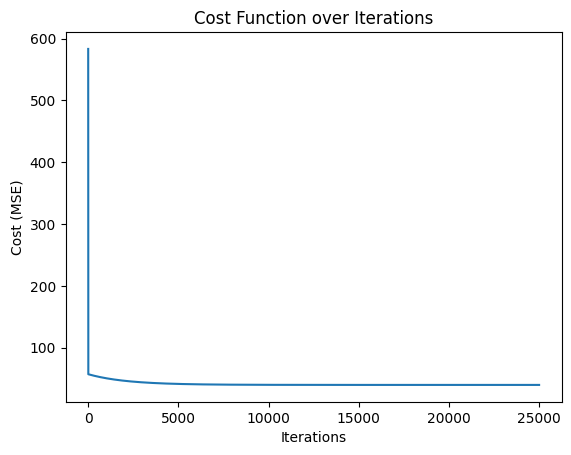

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(epochs), cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.title("Cost Function over Iterations")
plt.show()


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
degrees = [1, 2, 3, 5, 10]
for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X.reshape(-1, 1))
    model = LinearRegression()
    model.fit(X_poly, y)
    y_pred = model.predict(X_poly)
    mse = mean_squared_error(y, y_pred)
    print("Degree:", degree)
    print("MSE:", mse)
    print()


Degree: 1
MSE: 39.68105318671224

Degree: 2
MSE: 35.65546643377678

Degree: 3
MSE: 34.15936536720071

Degree: 5
MSE: 30.99539636765869

Degree: 10
MSE: 30.589786049109506



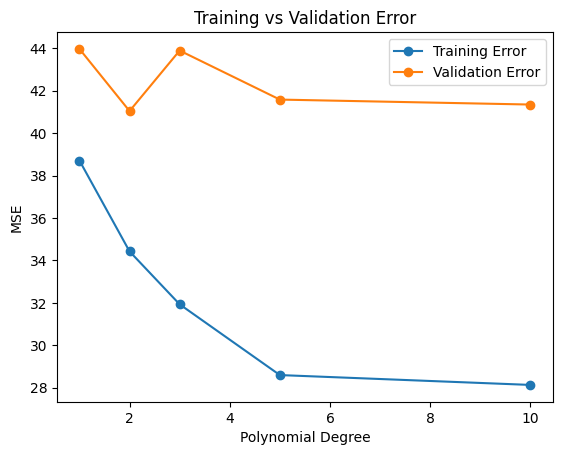

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)
degrees = [1, 2, 3, 5, 10]
train_errors = []
val_errors = []
for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
    X_val_poly = poly.transform(X_val.reshape(-1, 1))
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_train_pred = model.predict(X_train_poly)
    y_val_pred = model.predict(X_val_poly)
    train_errors.append(mean_squared_error(y_train, y_train_pred))
    val_errors.append(mean_squared_error(y_val, y_val_pred))
plt.plot(degrees, train_errors, marker='o', label="Training Error")
plt.plot(degrees, val_errors, marker='o', label="Validation Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.title("Training vs Validation Error")
plt.legend()
plt.show()


In [ ]:
best_degree = degrees[np.argmin(val_errors)]
print("Best degree:", best_degree)
for i in range(1, len(degrees)):
    if val_errors[i] > val_errors[i - 1]:
        print("Overfitting starts at degree:", degrees[i])
        break


Best degree: 2
Overfitting starts at degree: 3


In [ ]:
for degree, train, val in zip(degrees, train_errors, val_errors):
    print("Degree:", degree)
    print("Training MSE:", train)
    print("Validation MSE:", val)
    if val > train * 1.5:
        print("Behavior: High variance / Overfitting")
    elif train > val * 1.5:
        print("Behavior: High bias / Underfitting")
    else:
        print("Behavior: Balanced")
    print()

Degree: 1
Training MSE: 38.70833331880683
Validation MSE: 43.971497606584336
Behavior: Balanced

Degree: 2
Training MSE: 34.42360220015448
Validation MSE: 41.041610250487416
Behavior: Balanced

Degree: 3
Training MSE: 31.928110770980844
Validation MSE: 43.89371984672219
Behavior: Balanced

Degree: 5
Training MSE: 28.592095394024103
Validation MSE: 41.5825257481435
Behavior: Balanced

Degree: 10
Training MSE: 28.12746133114727
Validation MSE: 41.34861452859369
Behavior: Balanced



Training Size: 50
Training MSE: 32.407670223447994
Validation MSE: 43.90806230031868

Training Size: 100
Training MSE: 49.137508614274154
Validation MSE: 45.15211202405509

Training Size: 200
Training MSE: 41.484115347222065
Validation MSE: 44.191243709424796

Training Size: 300
Training MSE: 39.789894371894974
Validation MSE: 43.74496201581642

Training Size: 400
Training MSE: 38.708333318806815
Validation MSE: 43.9714976065845



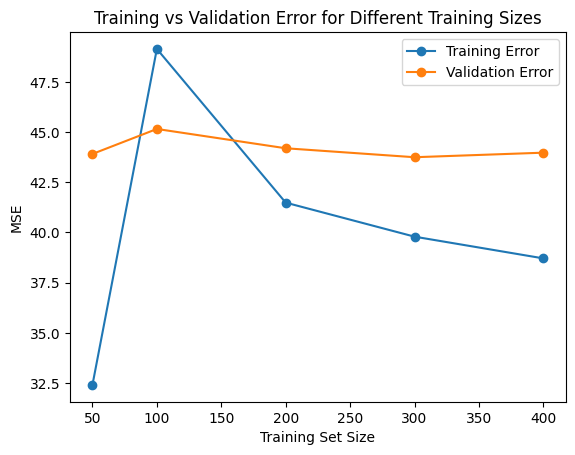

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
sizes = [50, 100, 200, 300, 400]
train_errors = []
val_errors = []
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for size in sizes:
    model = LinearRegression()
    model.fit(X_train[:size].reshape(-1, 1), y_train[:size])
    y_train_pred = model.predict(X_train[:size].reshape(-1, 1))
    y_val_pred = model.predict(X_val.reshape(-1, 1))
    train_errors.append(
        mean_squared_error(y_train[:size], y_train_pred)
    )
    val_errors.append(
    mean_squared_error(y_val, y_val_pred)
    )

    print("Training Size:", size)
    print("Training MSE:", train_errors[-1])
    print("Validation MSE:", val_errors[-1])
    print()
plt.plot(sizes, train_errors, marker='o', label="Training Error")
plt.plot(sizes, val_errors, marker='o', label="Validation Error")
plt.xlabel("Training Set Size")
plt.ylabel("MSE")
plt.title("Training vs Validation Error for Different Training Sizes")
plt.legend()
plt.show()
